In [2]:
import numpy as np
import pandas as pd

In [7]:
df = pd.read_csv('placement.csv')
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [9]:
df.shape

(100, 4)

In [10]:
df = df.iloc[:,1:]

In [11]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [ ]:
# Steps

# 0. Preprocess + EDA + Feature Selection
# 1. Extract input and output cols
# 2. Scale the values
# 3. Train test split
# 4. Train the model
# 5. Evaluate the model/model selection
# 6. Deploy the model

In [13]:
import matplotlib.pyplot as plt


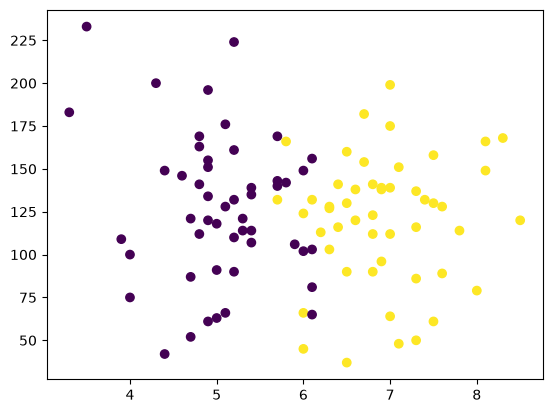

In [14]:
plt.scatter(df['cgpa'],df['iq'],c=df['placement'])

In [15]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [16]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [17]:
y.shape

(100,)

In [18]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.1)

In [19]:
X_train

,cgpa,iq
33,6.0,149.0
67,5.0,118.0
31,3.9,109.0
93,6.8,112.0
24,4.7,121.0
...,...,...
72,7.3,116.0
74,6.7,154.0
96,4.4,42.0
8,6.1,156.0


In [20]:
y_train

33    0
67    0
31    0
93    1
24    0
     ..
72    1
74    1
96    0
8     0
13    1
Name: placement, Length: 90, dtype: int64

In [21]:
X_test

,cgpa,iq
36,5.7,140.0
89,4.9,151.0
99,6.2,113.0
32,7.0,139.0
56,6.1,65.0
61,7.3,137.0
53,8.3,168.0
84,5.7,169.0
2,5.3,121.0
9,5.1,66.0


In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
scaler = StandardScaler()

In [24]:
X_train = scaler.fit_transform(X_train)

In [25]:
X_train

array([[ 0.02418758,  0.64115902],
       [-0.84656522, -0.12955777],
       [-1.8043933 , -0.35331426],
       [ 0.72078982, -0.27872876],
       [-1.10779106, -0.05497227],
       [-0.75948994,  1.31242849],
       [ 0.89494038, -1.4720967 ],
       [ 1.41739206,  0.11906055],
       [-0.9336405 , -0.0798341 ],
       [ 2.20106957, -0.0798341 ],
       [ 1.41739206, -0.8505509 ],
       [ 0.28541342,  0.11906055],
       [ 1.85276845,  1.06381017],
       [-2.15269442,  2.72955291],
       [ 0.45956398, -0.82568906],
       [-1.19486634,  0.56657353],
       [ 0.8078651 ,  0.36767887],
       [-0.14996298,  0.4671262 ],
       [-0.4982641 , -0.2290051 ],
       [-0.67241466,  0.93950101],
       [ 0.98201566,  0.69088269],
       [-0.67241466, -0.32845242],
       [ 0.54663926,  0.36767887],
       [ 0.8078651 , -0.67651807],
       [-0.14996298,  1.06381017],
       [ 0.63371454,  1.46159948],
       [-1.02071578,  0.44226437],
       [-0.67241466,  2.50579642],
       [-1.02071578,

In [26]:
X_test = scaler.transform(X_test)

In [27]:
X_test

array([[-0.23703826,  0.41740253],
       [-0.9336405 ,  0.69088269],
       [ 0.19833814, -0.25386693],
       [ 0.89494038,  0.3925407 ],
       [ 0.11126286, -1.44723486],
       [ 1.15616622,  0.34281704],
       [ 2.02691901,  1.11353383],
       [-0.23703826,  1.13839566],
       [-0.58533938, -0.05497227],
       [-0.75948994, -1.42237303]])

In [28]:
from sklearn.linear_model import LogisticRegression

In [29]:
clf = LogisticRegression()

In [30]:
# model training
clf.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [31]:
y_pred = clf.predict(X_test)

In [32]:
y_test

36    0
89    0
99    1
32    1
56    0
61    1
53    1
84    0
2     0
9     0
Name: placement, dtype: int64

In [33]:
from sklearn.metrics import accuracy_score

In [34]:
accuracy_score(y_test,y_pred)

0.9

In [37]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

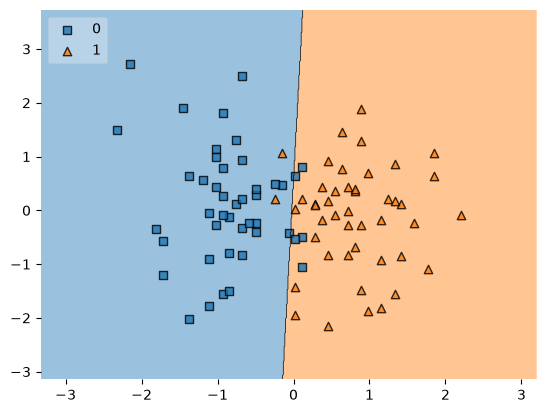

In [38]:
plot_decision_regions(X_train, y_train.values, clf=clf, legend=2)

In [39]:
import pickle

In [104]:
pickle.dump(clf,open('model.pkl','wb'))